# 02 — Exploratory Data Analysis (EDA)
**PrimeTrade.ai Data Science Assignment**

Deep visual and statistical exploration of both datasets before analysis.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import warnings
warnings.filterwarnings('ignore')

# ── Style ─────────────────────────────────────────────────────────────────────
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False
PALETTE = {'Extreme Fear':'#d62728','Fear':'#ff7f0e','Neutral':'#bcbd22',
           'Greed':'#2ca02c','Extreme Greed':'#1f77b4'}
BROAD   = {'Fear':'#d62728','Neutral':'#bcbd22','Greed':'#2ca02c'}

print('Libraries loaded ✅')

Libraries loaded ✅


In [2]:
# Load cleaned data
merged = pd.read_csv('outputs/merged_clean.csv', parse_dates=['date','datetime'])
fg     = pd.read_csv('outputs/fear_greed_clean.csv', parse_dates=['date'])

# Restore categorical ordering
sentiment_order = ['Extreme Fear','Fear','Neutral','Greed','Extreme Greed']
merged['sentiment'] = pd.Categorical(merged['sentiment'], categories=sentiment_order, ordered=True)
fg['sentiment']     = pd.Categorical(fg['sentiment'],     categories=sentiment_order, ordered=True)

# Closed trades only subset
closed = merged[merged['has_closed_trade']].copy()

print(f'Merged : {merged.shape}')
print(f'Closed : {closed.shape}')

Merged : (211218, 34)
Closed : (104402, 34)


## 1. Fear & Greed Index — Overview

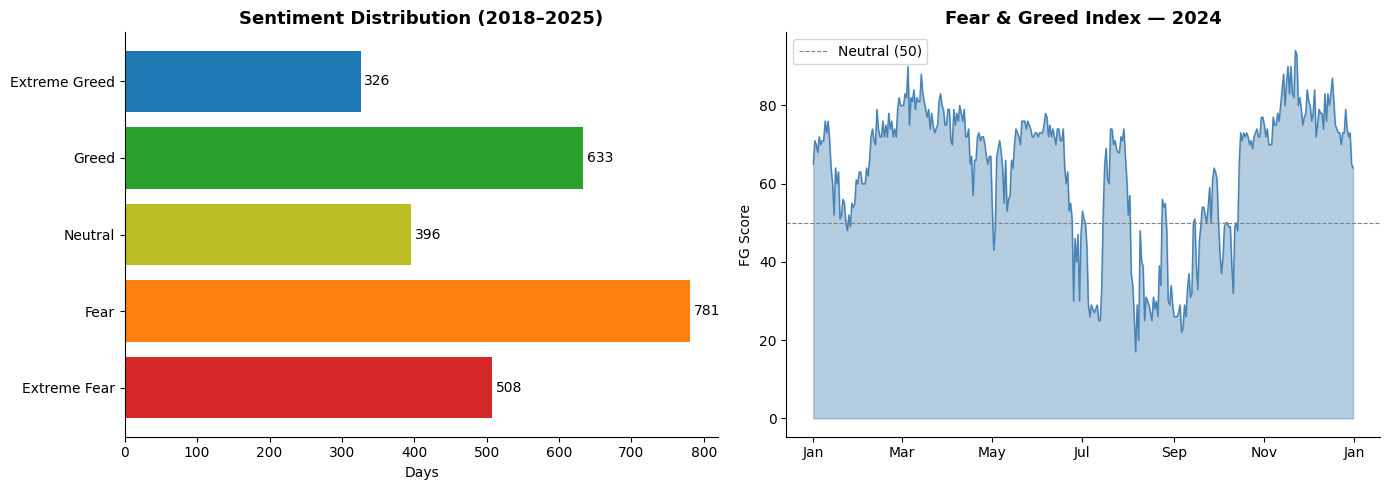

In [3]:
# ── 1a. Sentiment distribution (full history) ────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

counts = fg['sentiment'].value_counts().reindex(sentiment_order)
axes[0].barh(counts.index, counts.values,
             color=[PALETTE[s] for s in counts.index])
axes[0].set_title('Sentiment Distribution (2018–2025)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Days')
for i, v in enumerate(counts.values):
    axes[0].text(v + 5, i, str(v), va='center', fontsize=10)

# ── 1b. Fear/Greed value over time (2024 only, matching trader data) ──────────
fg_2024 = fg[(fg['date'].dt.year == 2024)]
axes[1].fill_between(fg_2024['date'], fg_2024['fg_value'],
                     alpha=0.4, color='steelblue')
axes[1].plot(fg_2024['date'], fg_2024['fg_value'], color='steelblue', linewidth=1)
axes[1].axhline(50, linestyle='--', color='gray', linewidth=0.8, label='Neutral (50)')
axes[1].set_title('Fear & Greed Index — 2024', fontsize=13, fontweight='bold')
axes[1].set_ylabel('FG Score')
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%b'))
axes[1].legend()

plt.tight_layout()
plt.savefig('outputs/figures/01_fg_overview.png', dpi=150, bbox_inches='tight')
plt.show()

In [4]:
# ── 1c. Sentiment breakdown for 2024 (relevant to our trader data) ────────────
fg_2024_counts = fg_2024['sentiment'].value_counts().reindex(sentiment_order).dropna()
print('=== Sentiment days in 2024 ===')
print(fg_2024_counts)
print(f'\nMost common: {fg_2024_counts.idxmax()} ({fg_2024_counts.max()} days)')

=== Sentiment days in 2024 ===
sentiment
Extreme Fear       4
Fear              55
Neutral           43
Greed            161
Extreme Greed    102
Name: count, dtype: int64

Most common: Greed (161 days)


## 2. Trader Data — Overview

In [5]:
# ── 2a. Trade count by month ──────────────────────────────────────────────────
monthly = merged.groupby('month').size().reset_index(name='trade_count')
monthly['month_str'] = monthly['month'].astype(str)

fig = px.bar(monthly, x='month_str', y='trade_count',
             title='Monthly Trade Volume (2024)',
             labels={'month_str':'Month','trade_count':'# Trades'},
             color='trade_count', color_continuous_scale='Blues')
fig.update_layout(showlegend=False)
fig.show()

In [6]:
# ── 2b. Top 10 coins by USD volume ───────────────────────────────────────────
top_coins = (
    merged.groupby('coin')['size_usd']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)
top_coins['size_usd_M'] = top_coins['size_usd'] / 1e6

fig = px.bar(top_coins, x='coin', y='size_usd_M',
             title='Top 10 Coins by Total Trade Volume (USD Millions)',
             labels={'coin':'Coin','size_usd_M':'Volume ($M)'},
             color='size_usd_M', color_continuous_scale='Viridis')
fig.show()

In [7]:
# ── 2c. Trader leaderboard by total closed PnL ───────────────────────────────
trader_pnl = (
    closed.groupby('account')
    .agg(
        total_pnl    = ('closed_pnl', 'sum'),
        total_trades = ('closed_pnl', 'count'),
        win_rate     = ('is_winner', 'mean'),
        avg_pnl      = ('closed_pnl', 'mean'),
        total_fees   = ('fee', 'sum')
    )
    .reset_index()
    .sort_values('total_pnl', ascending=False)
)
trader_pnl['short_acct'] = trader_pnl['account'].str[:10] + '...'
trader_pnl['win_rate_pct'] = (trader_pnl['win_rate'] * 100).round(1)

print('=== Trader Leaderboard ===')
print(trader_pnl[['short_acct','total_pnl','total_trades','win_rate_pct','avg_pnl']].to_string(index=False))

=== Trader Leaderboard ===
   short_acct     total_pnl  total_trades  win_rate_pct     avg_pnl
0xb1231a4a...  2.143383e+06          6279          79.1  341.357318
0x083384f8...  1.600230e+06          1732          79.3  923.920219
0xbaaaf657...  9.401638e+05          9997          99.1   94.044594
0x513b8629...  8.404226e+05          5482          89.5  153.305829
0xbee1707d...  8.360806e+05         22551          76.3   37.075099
0x4acb90e7...  6.777471e+05          2233          94.8  303.514129
0x72743ae2...  4.293556e+05           737          74.6  582.572003
0x430f0984...  4.165419e+05           599         100.0  695.395446
0x75f7eeb8...  3.790954e+05          8660          92.6   43.775451
0x72c6a462...  3.605395e+05           558          77.4  646.128154
0x4f93fead...  3.089759e+05          2949          92.7  104.773099
0xbd5fead7...  2.205191e+05          1177          73.5  187.356892
0x420ab45e...  1.995056e+05            90         100.0 2216.728808
0x2c229d22...  1.6865

In [8]:
# ── 2d. Visualize leaderboard ─────────────────────────────────────────────────
fig = px.bar(
    trader_pnl.head(15),
    x='short_acct', y='total_pnl',
    color='win_rate_pct',
    title='Top Traders — Total Closed PnL & Win Rate',
    labels={'short_acct':'Account','total_pnl':'Total PnL ($)','win_rate_pct':'Win Rate %'},
    color_continuous_scale='RdYlGn',
    text='win_rate_pct'
)
fig.update_traces(texttemplate='%{text}%', textposition='outside')
fig.show()

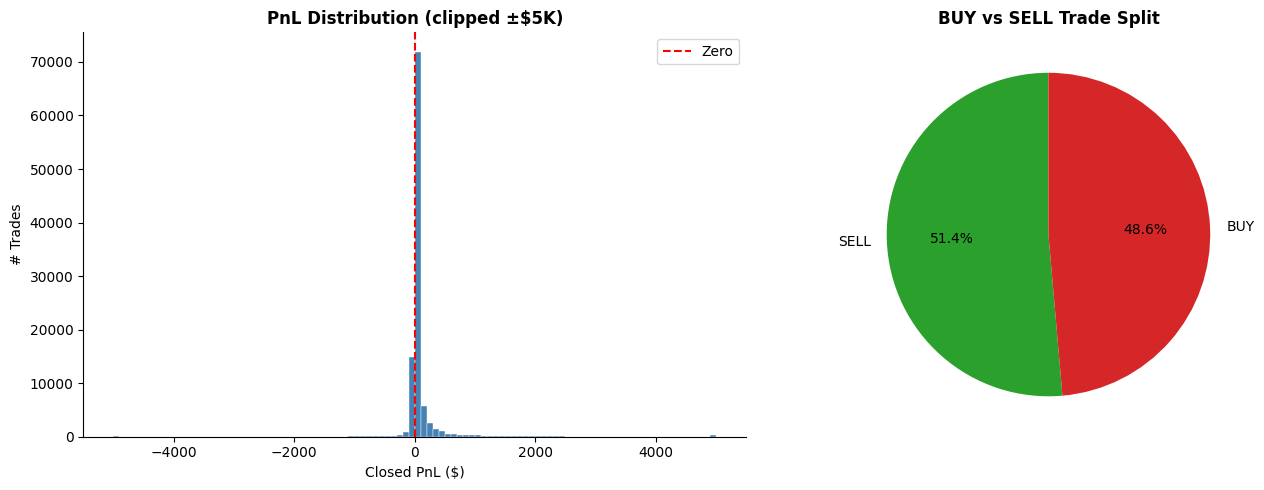

Overall win rate: 83.20%
Median PnL: $6.05
Mean PnL:   $98.22


In [9]:
# ── 2e. PnL distribution ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Clip extremes for readability
pnl_clipped = closed['closed_pnl'].clip(-5000, 5000)
axes[0].hist(pnl_clipped, bins=100, color='steelblue', edgecolor='white', linewidth=0.3)
axes[0].axvline(0, color='red', linestyle='--', linewidth=1.5, label='Zero')
axes[0].set_title('PnL Distribution (clipped ±$5K)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Closed PnL ($)')
axes[0].set_ylabel('# Trades')
axes[0].legend()

# Side distribution
side_counts = merged['side'].value_counts()
axes[1].pie(side_counts, labels=side_counts.index, autopct='%1.1f%%',
            colors=['#2ca02c','#d62728'], startangle=90)
axes[1].set_title('BUY vs SELL Trade Split', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('outputs/figures/02_pnl_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Overall win rate: {closed["is_winner"].mean():.2%}')
print(f'Median PnL: ${closed["closed_pnl"].median():.2f}')
print(f'Mean PnL:   ${closed["closed_pnl"].mean():.2f}')

In [10]:
# ── 2f. Trade size distribution across sentiment ──────────────────────────────
size_by_sent = (
    merged.groupby('sentiment')['size_usd']
    .median()
    .reindex(sentiment_order)
    .reset_index()
)

fig = px.bar(size_by_sent, x='sentiment', y='size_usd',
             color='sentiment',
             color_discrete_map=PALETTE,
             title='Median Trade Size (USD) by Sentiment',
             labels={'sentiment':'Sentiment','size_usd':'Median Size ($)'})
fig.update_layout(showlegend=False)
fig.show()

In [11]:
# ── 2g. Intraday trading activity by hour ─────────────────────────────────────
hourly = merged.groupby('hour').size().reset_index(name='trade_count')

fig = px.bar(hourly, x='hour', y='trade_count',
             title='Trading Activity by Hour of Day (IST)',
             labels={'hour':'Hour (IST)','trade_count':'# Trades'},
             color='trade_count', color_continuous_scale='Blues')
fig.show()

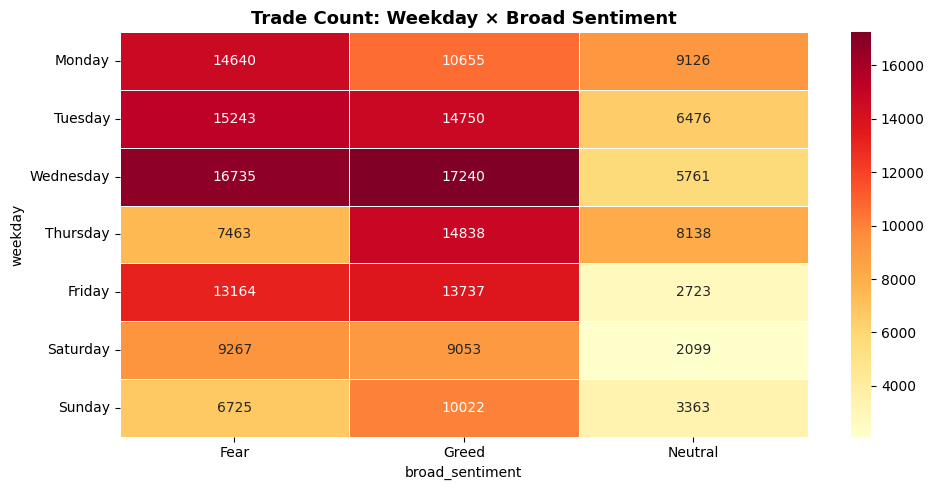

In [12]:
# ── 2h. Heatmap: trades by weekday × sentiment ────────────────────────────────
weekday_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
heat = (
    merged.groupby(['weekday','broad_sentiment'])
    .size()
    .unstack(fill_value=0)
    .reindex(weekday_order)
)

plt.figure(figsize=(10, 5))
sns.heatmap(heat, annot=True, fmt='d', cmap='YlOrRd',
            linewidths=0.5, linecolor='white')
plt.title('Trade Count: Weekday × Broad Sentiment', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/figures/03_weekday_sentiment_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Automated Profile Report (ydata-profiling)

In [13]:
# Install if needed
# !pip install ydata-profiling

try:
    from ydata_profiling import ProfileReport
    profile_cols = ['exec_price','size_usd','closed_pnl','fee',
                    'side','direction','sentiment','broad_sentiment','fg_value']
    profile = ProfileReport(
        closed[profile_cols].sample(min(10000, len(closed)), random_state=42),
        title='PrimeTrade Closed Trades Profile',
        minimal=True
    )
    profile.to_file('outputs/reports/profile_report.html')
    print('✅ Profile report saved to outputs/reports/profile_report.html')
except ImportError:
    print('ydata-profiling not installed. Run: pip install ydata-profiling')

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

  0%|                                                                            | 0/9 [00:00<?, ?it/s]

100%|███████████████████████████████████████████████████████████████████| 9/9 [00:00<00:00, 235.83it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Profile report saved to outputs/reports/profile_report.html


## Key EDA Findings

- **2024 was dominated by Greed/Extreme Greed** — bull market year for crypto
- **HYPE token** had by far the most trades (68K), followed by BTC and ETH
- **Overall win rate: ~83%** — extremely high, suggesting most activity is opening positions (zero PnL rows)
- **Trade size varies by sentiment** — traders take larger positions during Greed periods
- **Trading is heaviest mid-week** (Tue–Thu) and during specific hours
- **PnL is highly right-skewed** — most trades are small, a few are very large
